In [12]:
import numpy as np
from numpy import linspace, sqrt
import matplotlib.pyplot as plt
from scipy.special import jv, hankel2, hankel1, yv, jvp

## We first consider a metallic cylinder, of radius $R$, in vacuum. In this case, the potential is given by the following: 

## $\begin{align*}\phi(r<R)=Ar^{m}-\frac{B}{\varepsilon_\infty k_{NL}^2}J_m(k_{NL}r), \phi(r>R)=r^{-m} \end{align*}$

## We have the following three boundary conditions: 

## $\begin{align*}&AR^m-\frac{B}{\varepsilon_\infty k_{NL}^2} J_m(k_{NL}R)=R^{-m},  \varepsilon_\infty mAR^{m-1} - \frac{B}{k_{NL}} J_m'(k_{NL}R)=-m\varepsilon_B R^{-m-1} \\& -\frac{\omega_p^2\varepsilon_Bm}{\varepsilon_\infty}R^{-m-1}-\beta^2 k_{NL}BJ_m'(k_{NL}R)=0 \end{align*}$

## This then gives us the following: 

## $\begin{align*} &B = -\frac{\omega_p^2\varepsilon_B m R^{-m-1}}{\varepsilon_\infty\beta^2 k_{NL}J_m'(k_{NL}R)}, A = -\frac{\varepsilon_B R^{-2m}}{\varepsilon_\infty} \Bigg[1+\frac{\omega_p^2}{\varepsilon_\infty \beta^2 k_{NL}^2} \Bigg] \\& -\frac{\varepsilon_B}{\varepsilon_\infty}\Bigg[1+\frac{\omega_p^2}{\varepsilon_\infty \beta^2 k_{NL}^2} \Bigg]+\frac{\omega_p^2\varepsilon_B m}{\varepsilon_\infty^2 \beta^2 k_{NL}^2}\frac{J_m(k_{NL}R)}{(k_{NL}R) J_m'(k_{NL}R)}=1\end{align*}$

## We now use the fact that $\begin{align*}\frac{\omega_p^2/\varepsilon_\infty}{\beta^2 k_{NL}^2}=\frac{\omega_p^2/\varepsilon_\infty}{\omega(\omega+i\gamma)-\omega_p^2/\varepsilon_\infty} =\frac{\varepsilon_\infty-\varepsilon_D}{\varepsilon_D}\end{align*}$

## $\begin{align*}&-\frac{\varepsilon_B}{\varepsilon_D}+\frac{\varepsilon_\infty-\varepsilon_D}{\varepsilon_D}\frac{m\varepsilon_B}{\varepsilon_\infty}\frac{J_m(k_{NL}R)}{(k_{NL}R)J_m'(k_{NL}R)}=1 \rightarrow \\ & \varepsilon_B\Bigg[1+\frac{\varepsilon_D-\varepsilon_\infty}{\varepsilon_\infty}\frac{mJ_m(k_{NL}R)}{(k_{NL}R) J_m'(k_{NL}R)} \Bigg] +\varepsilon_D = 0 \end{align*}$

## Thus, the dispersion relation is approximately given by the following: 

## $\begin{align*}2\omega(\omega+i\gamma)-\omega_p^2\Bigg[1+\frac{i}{k_{NL}R} \Bigg]\approx 2\omega(\omega+i\gamma)-\omega_p^2\Bigg[1+\frac{\sqrt{2}\beta}{R\omega_p}\Bigg[1-\frac{iD\omega_p}{2\sqrt{2}\beta^2} \Bigg] \Bigg] \end{align*}$

## Thus, we find: 

## $\begin{align*}\omega \approx \frac{\omega_p}{\sqrt{2}}-\frac{i\gamma}{2}+\frac{\beta}{2R}\Bigg[1-\frac{iD\omega_p}{2\sqrt{2}\beta^2}\Bigg]\end{align*}$

In [4]:
def cylindrical_polarizability_denom(x, omega, gamma=1e-2, v_F=1e-3, dfrac=0.1):
    # x = R*omega/c, where R is the radius, c is the speed of light
    # v_F is the Fermi velocity in units of the speed of light 
    # gamma is the bulk scattering rate, given in units of the plasma frequency
    # omega is the frequency given in units of the plasma frequency
    # dfrac is the dimensionless constant we previously mentioned
    epsilon = 1 - 1/(omega**2+1j*omega*gamma) # Drude dielectric funtion 
                                              # (corresponding to the permittivity of the sphere 
                                              # for epsilon_infinity = 1
    beta = sqrt(3/5)*v_F # Corresponds to pressure forces, valid in the high-frequency limit
    omega_p = 1 # Plasma frequency in the units of the plasma frequency lol...
    D = dfrac*(v_F**2)/omega_p # Diffusion constant
    
    eta_sqrd = beta**2 + D*gamma - 1j*D*omega 
    knl_sqrd = (epsilon/(1-epsilon))*(1/eta_sqrd)*(1/omega**2)  
    knl = sqrt(knl_sqrd) # k_nl * R in standard notation will be given by k_nl * x 

    z = x * knl # longitudinal mode's normalized wavenumber
    delta = (epsilon-1)*(jv(1, z)/(z*jvp(1, z, 1)))
    # The expression for delta could be numerically unstable in some regions...I have not had issues with this so far though...
    return epsilon + (1+delta)


In [30]:
N_Rs = 200 # Number of radii for which we find the resonance frequencies
N_omegas = 500 # Number of frequency points sampled 
Rs = linspace(1, 15, N_Rs) # Radii in nanometers
hbar_omega_p = 10 # hbar multiplied by the plasma frequency (in eV)
hbar_c = 200 # hbar multiplied by the speed of light in eV*nm
dfrac = 0.7 # Dimensionless multiplier of the diffusion constant

v_F = 1e-3; beta = sqrt(3/5)*v_F; gamma = 1e-2; omega_p = 1; D = dfrac*(v_F**2)/omega_p # Diffusion constant

omegas_real = linspace(0.707, 0.72, N_omegas) # In units of omega_p
omegas_imag = linspace(0.004, 0.01, N_omegas) # In units of omega_p
omegas = omegas_real.reshape((N_omegas, 1)).repeat(N_omegas, axis=1) - 1j*omegas_imag.reshape((1, N_omegas)).repeat(N_omegas, axis=0)

best_omega_reals = []
best_omega_imags = []

for R in Rs:
    polarizability_map = cylindrical_polarizability_denom(R*omegas*hbar_omega_p/hbar_c, omegas, gamma=gamma, v_F=v_F, dfrac=dfrac)
    best_omega = omegas.flatten()[np.abs(polarizability_map).argmin()].item()
    best_omega_reals.append(best_omega.real)
    best_omega_imags.append(best_omega.imag)
best_omega_reals = np.array(best_omega_reals)
best_omega_imags = np.array(best_omega_imags)

In [31]:
best_omega_reals_approx = 1/sqrt(2) + (beta*hbar_c)/(2*Rs*hbar_omega_p)
best_omega_imags_approx = -gamma/2 - (1/(4*sqrt(2)))*(D)*hbar_c/(beta*Rs*hbar_omega_p)

Biggest error in blue shift approximation:  140.311 %


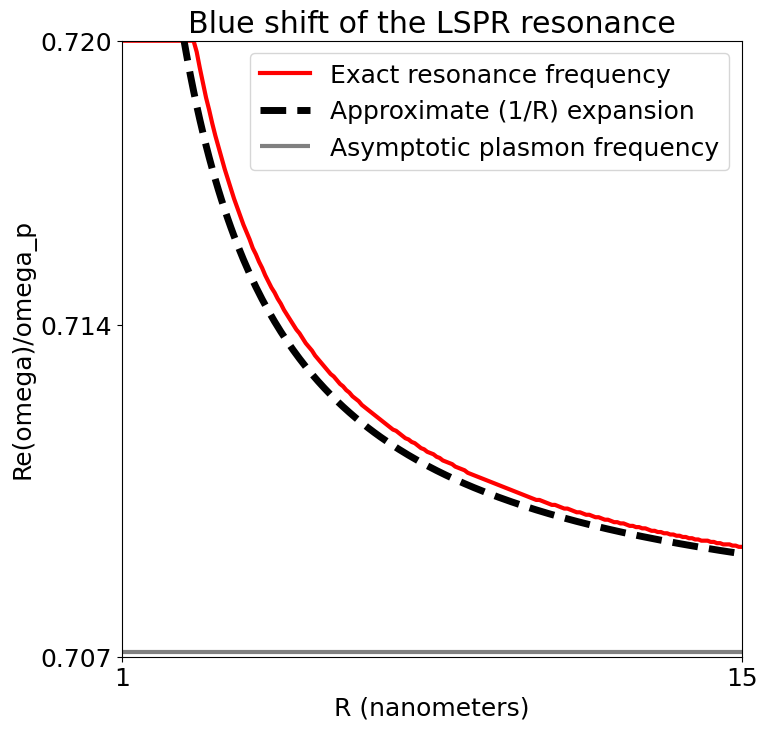

In [32]:
diff_num = best_omega_reals-best_omega_reals_approx
diff_denom = best_omega_reals-1/sqrt(2)
plt.rcParams.update({'font.size': 18})
fig, ax = plt.subplots(figsize=(8, 8))
ax.plot(Rs, best_omega_reals, color="red", label="Exact resonance frequency", linewidth=3)
ax.plot(Rs, best_omega_reals_approx, color="black", linestyle="dashed", linewidth=5, label="Approximate (1/R) expansion")
ax.hlines([1/sqrt(2)], Rs.min(), Rs.max(), color="Grey", linewidth=3, label="Asymptotic plasmon frequency");
ax.set_ylim(omegas_real.min(), omegas_real.max());
ax.set_xlim(Rs.min(), Rs.max());
ax.set_xlabel("R (nanometers)")
ax.set_ylabel("Re(omega)/omega_p");
ax.set_xticks([Rs.min(), Rs.max()])
ax.set_title("Blue shift of the LSPR resonance")
ax.legend();
print("Biggest error in blue shift approximation: ", np.abs(100*diff_num/diff_denom).max().round(3), "%")
ax.set_yticks([omegas_real.min().round(3), ((omegas_real.min()+omegas_real.max())/2).round(3), omegas_real.max().round(3)]);


Biggest error in Kreibig approximation:  10.028 %


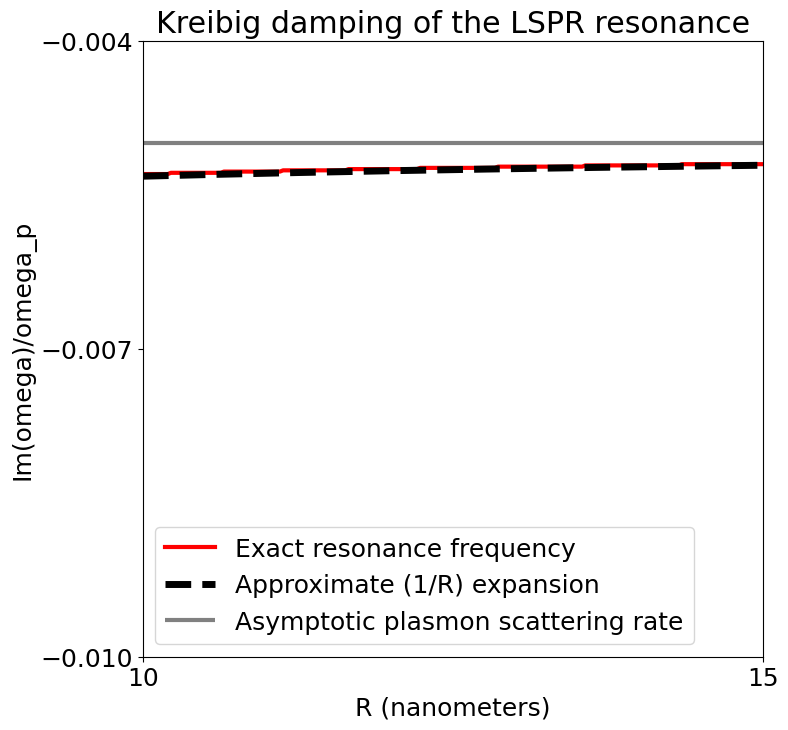

In [28]:
diff_num = best_omega_imags - best_omega_imags_approx
diff_denom = best_omega_imags + gamma/2
plt.rcParams.update({'font.size': 18})
fig, ax = plt.subplots(figsize=(8, 8))
ax.plot(Rs, best_omega_imags, color="red", label="Exact resonance frequency", linewidth=3)
ax.plot(Rs, best_omega_imags_approx, color="black", linestyle="dashed", linewidth=5, label="Approximate (1/R) expansion")
ax.hlines([-gamma/2], Rs.min(), Rs.max(), color="Grey", linewidth=3, label="Asymptotic plasmon scattering rate");
ax.set_ylim(-omegas_imag.max(), -omegas_imag.min());
ax.set_xlim(Rs.min(), Rs.max());
ax.set_xlabel("R (nanometers)")
ax.set_ylabel("Im(omega)/omega_p");
ax.set_xticks([Rs.min(), Rs.max()])
ax.legend();
ax.set_yticks([-omegas_imag.min().round(3), -((omegas_imag.min()+omegas_imag.max())/2).round(3), -omegas_imag.max().round(3)]);
ax.set_title("Kreibig damping of the LSPR resonance");
print("Biggest error in Kreibig approximation: ", np.abs(100*diff_num/diff_denom).max().round(3), "%")